## Step 1: Extract the dataset
- /content/custom_data	Folder where the ZIP contents will be extracted

In [1]:
!unzip -q /content/Indian-Sweets-Savouries-YML-dataset-RAW.zip -d /content/custom_data

## Step 2: Download the splitting script

In [2]:
!wget -O /content/train_val_split.py \
https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py

--2026-11-09 12:49:26--  https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3203 (3.1K) [text/plain]
Saving to: ‘/content/train_val_split.py’

/content/train_val_ 100%[===================>]   3.13K  --.-KB/s    in 0s      

2026-11-09 12:49:26 (53.6 MB/s) - ‘/content/train_val_split.py’ saved [3203/3203]



## Step 3: Split the dataset

In [ ]:
!python train_val_split.py \
    --datapath="/content/custom_data" \
    --train_pct=0.9

Created folder at /content/data/train/images.
Created folder at /content/data/train/labels.
Created folder at /content/data/validation/images.
Created folder at /content/data/validation/labels.
Number of image files: 1005
Number of annotation files: 1005
Images moving to train: 904
Images moving to validation: 101


## Step 3.2 : If you also want test data
-If you also want a Test dataset, we need to modify the splitting process. The GitHub script in your notebook creates only Train and Validation folders.

In [3]:

import random
import shutil
from pathlib import Path

# Dataset paths
root = Path("/content/custom_data")
images_dir = root / "images"
labels_dir = root / "labels"

# Find images
extensions = {".jpg", ".jpeg", ".png", ".webp"}

images = [
    p for p in images_dir.iterdir()
    if p.suffix.lower() in extensions
]

# Match images with annotation files
pairs = []
missing = []

for img in images:
    label = labels_dir / f"{img.stem}.txt"

    if label.exists():
        pairs.append((img, label))
    else:
        missing.append(img.name)

print("Total images:", len(images))
print("Matched pairs:", len(pairs))
print("Missing labels:", len(missing))

if missing:
    raise ValueError("Some images have no matching labels.")

# Shuffle images
random.seed(42)
random.shuffle(pairs)

# Split 80/10/10
n = len(pairs)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

splits = {
    "train": pairs[:train_end],
    "val": pairs[train_end:val_end],
    "test": pairs[val_end:]
}

# Copy images and labels
for split, items in splits.items():

    img_out = root / split / "images"
    lbl_out = root / split / "labels"

    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)

    for img, label in items:
        shutil.copy2(img, img_out / img.name)
        shutil.copy2(label, lbl_out / label.name)

    print(f"{split}: {len(items)} images")

print("Dataset splitting completed!")


Total images: 1005
Matched pairs: 1005
Missing labels: 0
train: 804 images
val: 100 images
test: 101 images
Dataset splitting completed!


### !!! Important : Now Correct tha Training and validation paths in `data.yml`

## Step4: Creating `data.yml` file

Step 4.1:  Read your 132 class names

In [6]:
from pathlib import Path
import json

# Original Label Studio export
root = Path("/content/custom_data")

# Already split dataset
dataset_dir = Path("/content/custom_data")

# Read class names
classes_file = root / "classes.txt"

class_names = [
    line.strip()
    for line in classes_file.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

# Create YAML
yaml_content = f"""
path: {dataset_dir}
train: train/images
val: validation/images

nc: {len(class_names)}
names: {json.dumps(class_names, ensure_ascii=False)}
"""

# Save inside /content/data
yaml_path = dataset_dir / "data.yaml"
yaml_path.write_text(yaml_content.strip() + "\n", encoding="utf-8")

print(yaml_path.read_text())

path: /content/custom_data
train: train/images
val: validation/images

nc: 132
names: ["Appadam", "Arisalu", "Awan-Bangwi", "Badusha", "Bal-Mithai", "Bandar-Laddu", "Bebinca", "Bellam-Gavvalu", "Bobbatlu-Poli", "Carrot-Gajar-halwa", "Chak-Hao-Kheer_Nap-Naang", "Chhena-Poda", "Dehrori", "Double-ka-metha", "Dry-fruit-laddu", "Ela-Ada", "Ghevar", "Goan-khaje", "Gulab-jamun-thandai", "HalwaPuff", "Jackfruit-chips", "Jangri", "Jelebi", "Junnu-MilkPudding", "Kaju-Katori", "Kaju-chikki", "Kaju-kamal", "Kakinada-kaja", "Kalakandh-kalakani", "Kesari", "Khapse", "Koat-Pitha", "Laddu", "Langcha", "Malpua-Malpuri", "Mawa-Bati", "Milk-kova", "Mishti-doi", "Mothichur-laddu", "Murrukulu", "Onion-Pakodi", "Parwal-Mithai", "Pazham-Pori", "Peanut-chikki", "Phirni", "Pithas", "Purnam-Burelu", "Putharekulu", "Rabri-Basundi", "Rasagulla", "Rasamalai", "Regi-Vadiyalu", "Ribbon-pakoda", "Rose-laddu", "Roshkodom", "Sakin-Gata", "Sel-Roti", "Semya", "Shondesh", "Soan-papidi", "Thaati-tandra", "Thekua", "Tirupa

## Exporting Clean dataset with train_ valid splits

In [ ]:
import shutil

# Compress the complete dataset folder
shutil.make_archive(
    "/content/Indian_Food_YOLO_Dataset",
    "zip",
    "/content/data"
)

print("Dataset ZIP created successfully!, download from there")

Dataset ZIP created successfully!


# Data Training

In [7]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 13.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [8]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [38]:

model = YOLO("yolov8m.pt")

results = model.train(
    data="/content/custom_data/data.yaml",
    epochs=20
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/custom_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optim

## Yes the final part Prediction


image 1/1 /content/custom_data/images/3b29e642-kaju-casata7.jpg: 512x640 2 kaju-casatas, 30.5ms
Speed: 2.2ms preprocess, 30.5ms inference, 1.6ms postprocess per image at shape (1, 3, 512, 640)


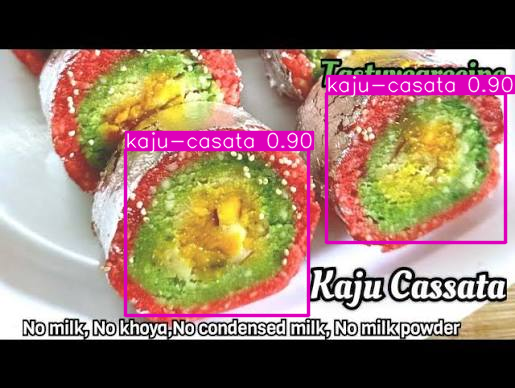

In [39]:
results=model.predict('/content/custom_data/images/3b29e642-kaju-casata7.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/048e3f6a-Kaju-kamal5.jpg: 640x384 1 Kaju-kamal, 26.5ms
Speed: 1.6ms preprocess, 26.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 384)


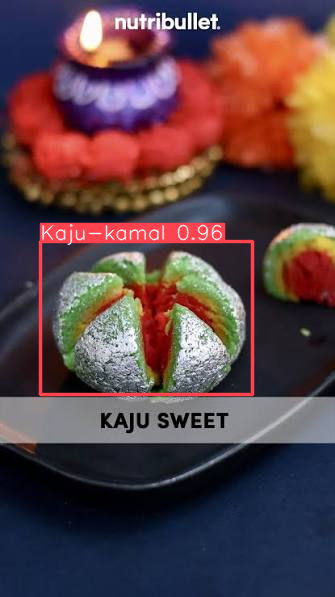

In [40]:
results=model.predict("/content/custom_data/test/images/048e3f6a-Kaju-kamal5.jpg")
results[0].show()


image 1/1 /content/custom_data/val/images/14dc3317-Bellam-Gavvalu6.jpg: 640x640 2 Bellam-Gavvalus, 38.4ms
Speed: 4.2ms preprocess, 38.4ms inference, 2.5ms postprocess per image at shape (1, 3, 640, 640)


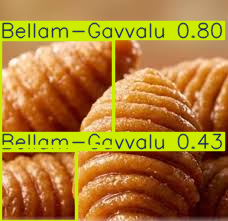

In [44]:
results=model.predict('/content/custom_data/val/images/14dc3317-Bellam-Gavvalu6.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/15c074cd-kaju-paan1.jpg: 480x640 2 Parwal-Mithais, 8 kaju-paans, 32.0ms
Speed: 3.5ms preprocess, 32.0ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 640)


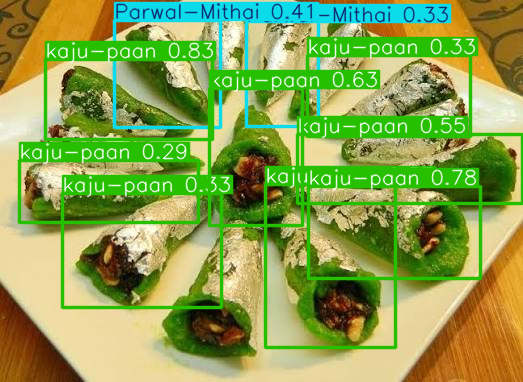

In [45]:
results=model.predict('/content/custom_data/test/images/15c074cd-kaju-paan1.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/16f08849-bengali-gujiya5.jpg: 640x384 4 bengali-gujiyas, 1 doodh-peda, 26.4ms
Speed: 2.0ms preprocess, 26.4ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 384)


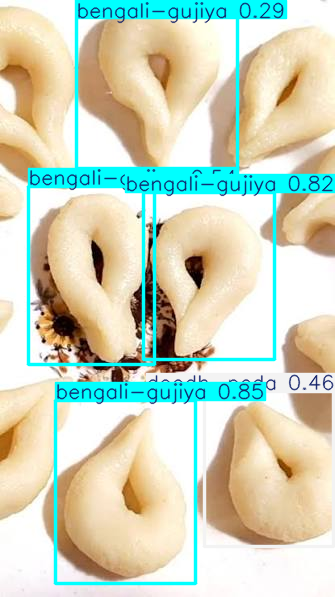

In [46]:
results=model.predict('/content/custom_data/test/images/16f08849-bengali-gujiya5.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/1f30df74-badam-ki-jali3.jpg: 640x480 13 badam-ki-jails, 30.7ms
Speed: 1.4ms preprocess, 30.7ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 480)


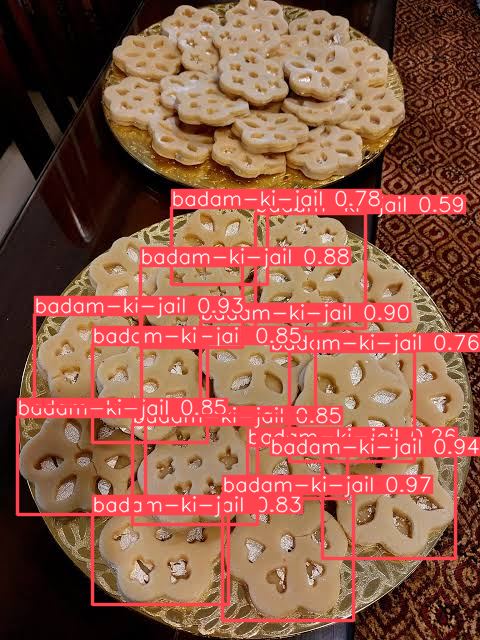

In [47]:
results=model.predict('/content/custom_data/test/images/1f30df74-badam-ki-jali3.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/440a58d9-Parwal-Mithai8.jpg: 480x640 5 Parwal-Mithais, 31.5ms
Speed: 2.1ms preprocess, 31.5ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)


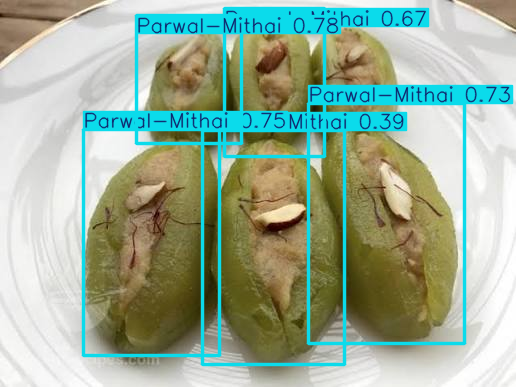

In [48]:
results=model.predict('/content/custom_data/test/images/440a58d9-Parwal-Mithai8.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/9b6ff73a-roses-flower10.jpg: 512x640 7 roses-flowers, 31.6ms
Speed: 1.9ms preprocess, 31.6ms inference, 1.5ms postprocess per image at shape (1, 3, 512, 640)


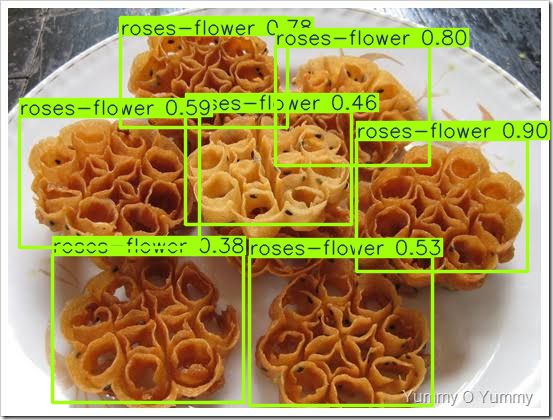

In [49]:
results=model.predict('/content/custom_data/test/images/9b6ff73a-roses-flower10.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/b1c003c9-chilakalu9.jpg: 512x640 1 Roshkodom, 6 chilakalus, 30.6ms
Speed: 1.9ms preprocess, 30.6ms inference, 1.6ms postprocess per image at shape (1, 3, 512, 640)


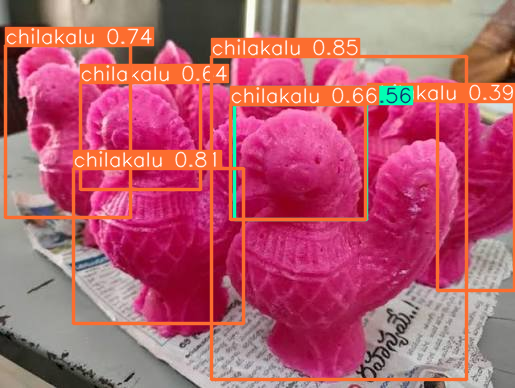

In [50]:
results=model.predict('/content/custom_data/test/images/b1c003c9-chilakalu9.jpg')
results[0].show()


image 1/1 /content/custom_data/val/images/1eece6f4-Semya.jpg: 640x448 1 Semya, 30.1ms
Speed: 2.6ms preprocess, 30.1ms inference, 4.3ms postprocess per image at shape (1, 3, 640, 448)


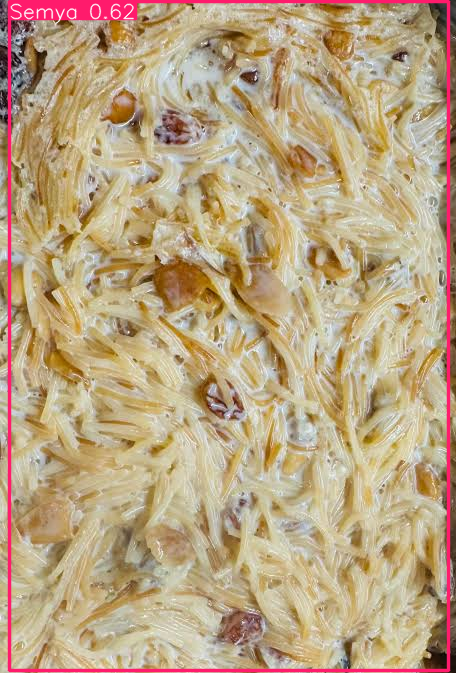

In [52]:
results=model.predict('/content/custom_data/val/images/1eece6f4-Semya.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/e089b828-Kaju-Katori7.jpg: 640x640 9 Kaju-Katoris, 39.4ms
Speed: 2.7ms preprocess, 39.4ms inference, 2.9ms postprocess per image at shape (1, 3, 640, 640)


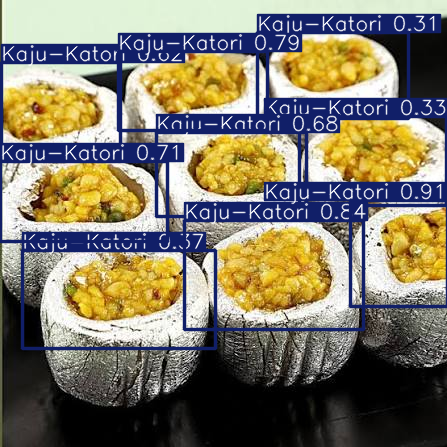

In [53]:
results=model.predict('/content/custom_data/test/images/e089b828-Kaju-Katori7.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/fe8d070f-small-chekodi.jpg: 576x640 9 small-chekodis, 36.7ms
Speed: 2.1ms preprocess, 36.7ms inference, 1.5ms postprocess per image at shape (1, 3, 576, 640)


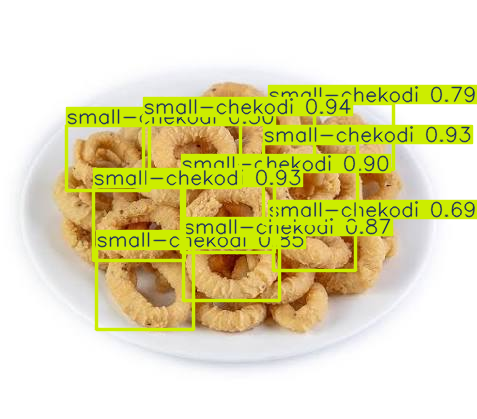

In [54]:
results=model.predict('/content/custom_data/test/images/fe8d070f-small-chekodi.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/ff2d573b-bhakarwadi6.jpg: 640x640 9 bhakarwadis, 39.6ms
Speed: 2.8ms preprocess, 39.6ms inference, 2.7ms postprocess per image at shape (1, 3, 640, 640)


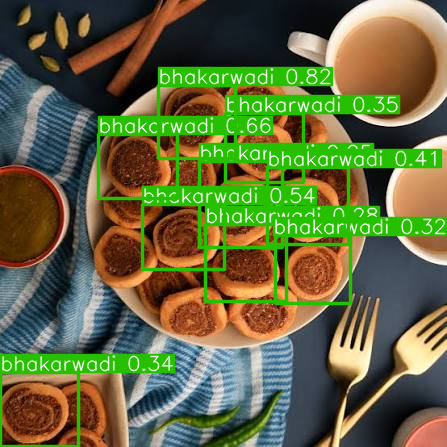

In [55]:
results=model.predict('/content/custom_data/test/images/ff2d573b-bhakarwadi6.jpg')
results[0].show()


image 1/1 /content/custom_data/val/images/2f7002bd-Bobbatlu-POLI10.jpg: 640x480 1 Bobbatlu-Poli, 57.4ms
Speed: 15.7ms preprocess, 57.4ms inference, 3.5ms postprocess per image at shape (1, 3, 640, 480)


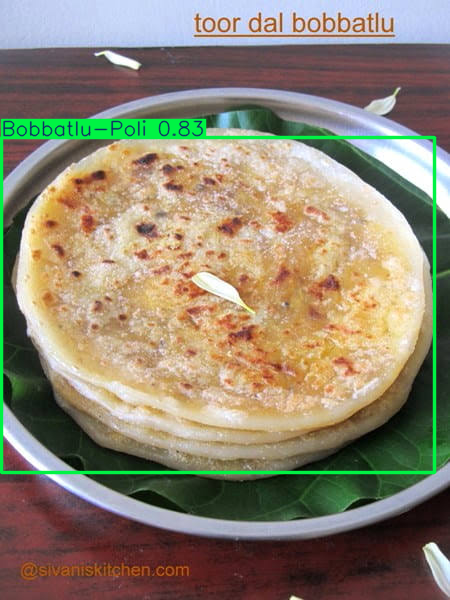

In [57]:
results=model.predict('/content/custom_data/val/images/2f7002bd-Bobbatlu-POLI10.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/27aec034-orange-candy.jpg: 640x640 6 orange-candys, 38.8ms
Speed: 4.8ms preprocess, 38.8ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)


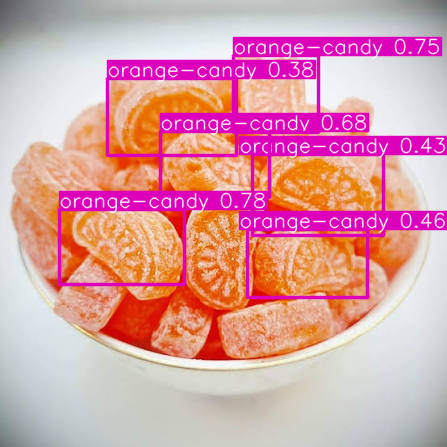

In [58]:
results=model.predict('/content/custom_data/test/images/27aec034-orange-candy.jpg')
results[0].show()


image 1/1 /content/custom_data/val/images/1eac11ad-halwa3.webp: 640x640 1 halwa, 37.4ms
Speed: 2.5ms preprocess, 37.4ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)


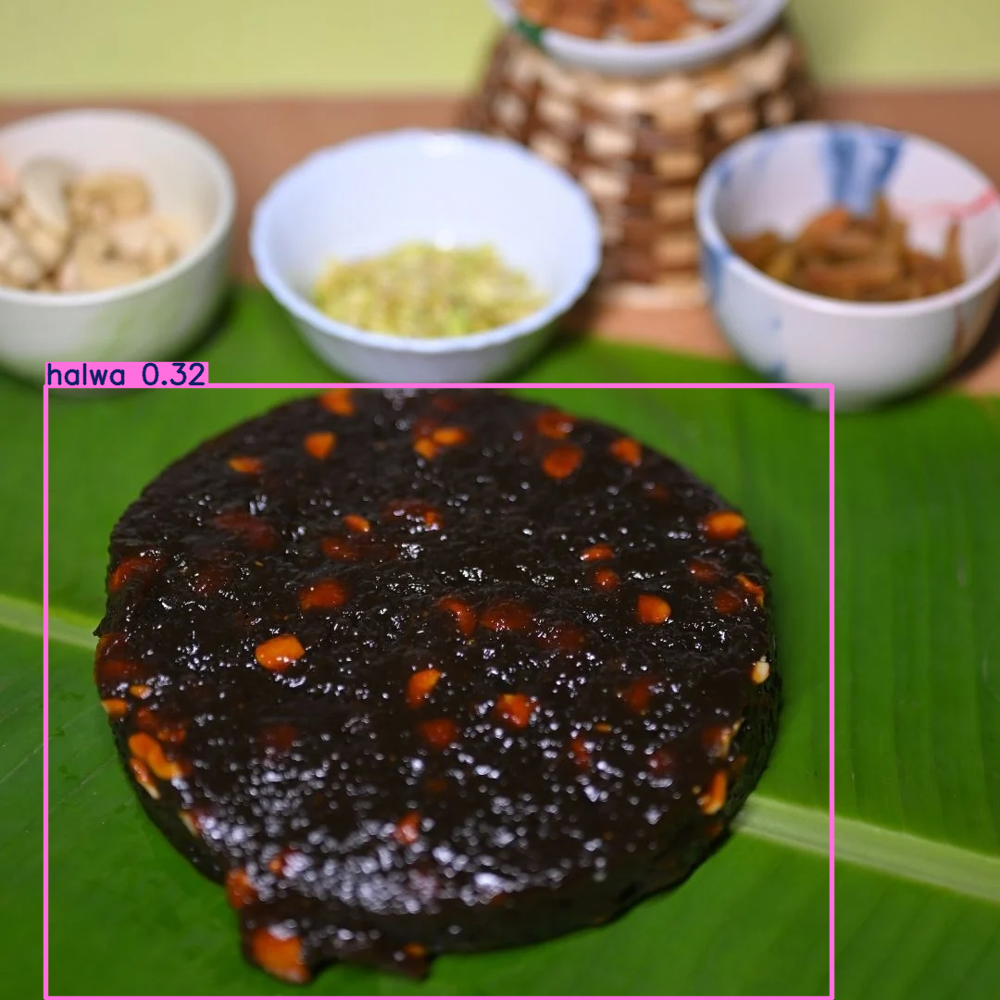

In [59]:
results=model.predict('/content/custom_data/val/images/1eac11ad-halwa3.webp')
results[0].show()


image 1/1 /content/custom_data/val/images/4fc59a73-Ribbon-pakoda.jpg: 640x448 1 Ribbon-pakoda, 57.8ms
Speed: 10.2ms preprocess, 57.8ms inference, 4.0ms postprocess per image at shape (1, 3, 640, 448)


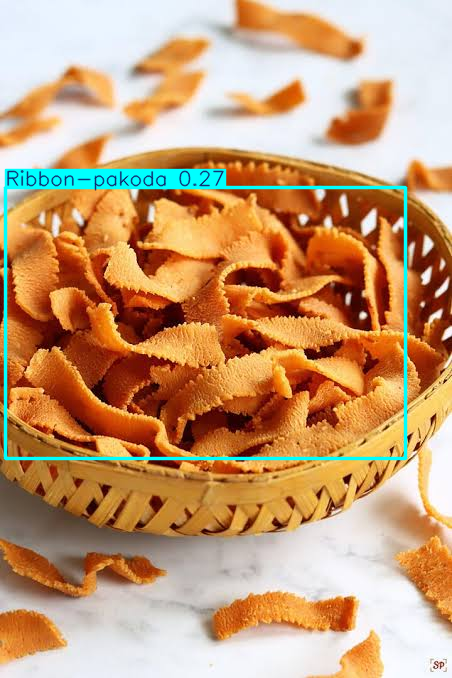

In [61]:
results=model.predict('/content/custom_data/val/images/4fc59a73-Ribbon-pakoda.jpg')
results[0].show()


image 1/1 /content/custom_data/val/images/6ad9a79c-petha4.jpg: 640x640 1 moong-dal, 40.0ms
Speed: 3.9ms preprocess, 40.0ms inference, 2.6ms postprocess per image at shape (1, 3, 640, 640)


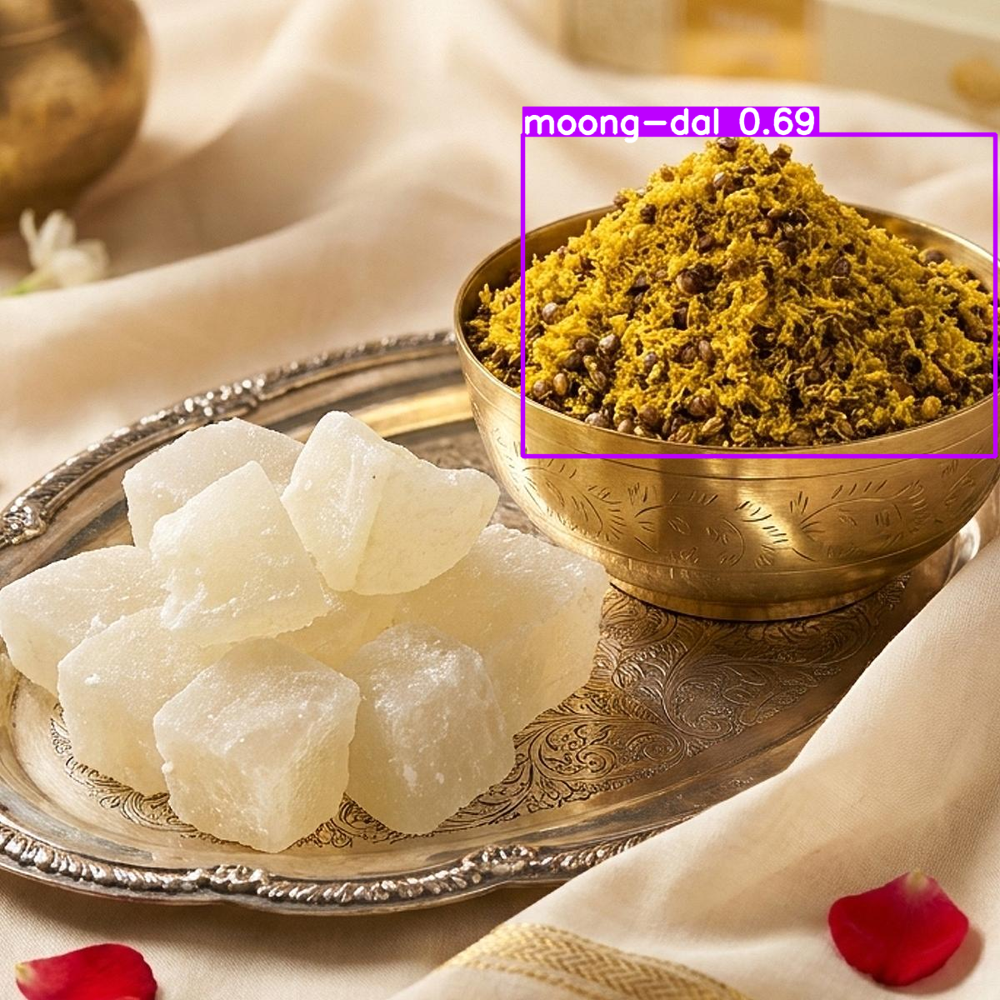

In [64]:
results=model.predict('/content/custom_data/val/images/6ad9a79c-petha4.jpg')
results[0].show()


image 1/1 /content/custom_data/val/images/92f9b005-pistachio-roll7.jpg: 448x640 1 pistachio-roll, 33.3ms
Speed: 6.1ms preprocess, 33.3ms inference, 4.3ms postprocess per image at shape (1, 3, 448, 640)


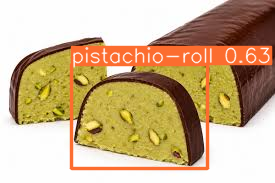

In [66]:
results=model.predict('/content/custom_data/val/images/92f9b005-pistachio-roll7.jpg')
results[0].show()


image 1/1 /content/custom_data/val/images/9e73a1f4-jantikalu5.jpg: 640x640 3 jantikalus, 39.6ms
Speed: 2.9ms preprocess, 39.6ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 640)


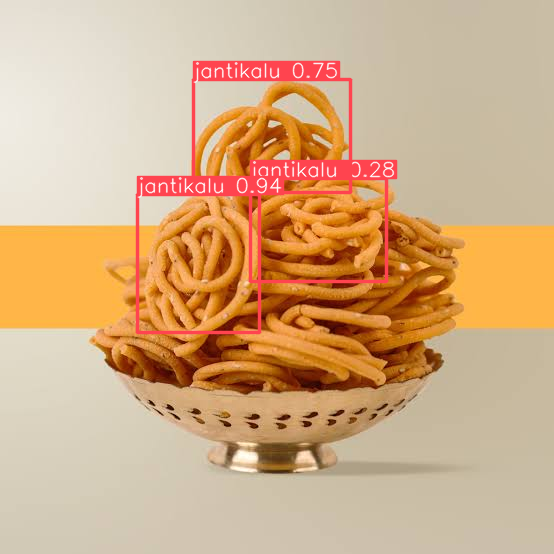

In [67]:
results=model.predict('/content/custom_data/val/images/9e73a1f4-jantikalu5.jpg')
results[0].show()


image 1/1 /content/custom_data/val/images/eedeaac5-Carrot-Gajar-halwa1.jpg: 640x384 1 Carrot-Gajar-halwa, 30.5ms
Speed: 3.8ms preprocess, 30.5ms inference, 2.6ms postprocess per image at shape (1, 3, 640, 384)


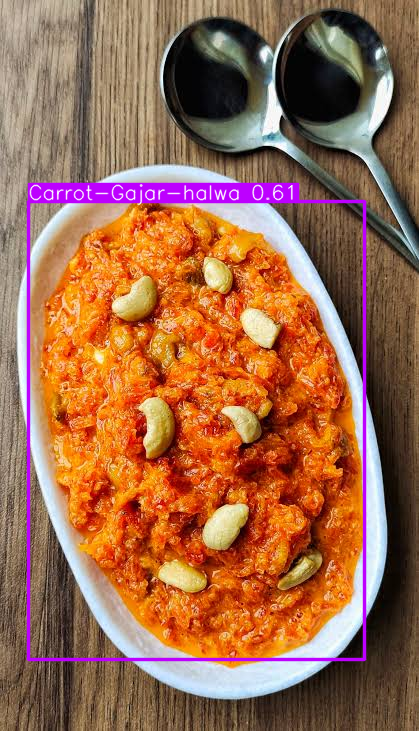

In [69]:
results=model.predict('/content/custom_data/val/images/eedeaac5-Carrot-Gajar-halwa1.jpg')
results[0].show()


image 1/1 /content/custom_data/val/images/f944507b-srawberry-kova.jpg: 416x640 2 cashew-roseFlowers, 4 srawberry-kovas, 45.3ms
Speed: 1.7ms preprocess, 45.3ms inference, 1.7ms postprocess per image at shape (1, 3, 416, 640)


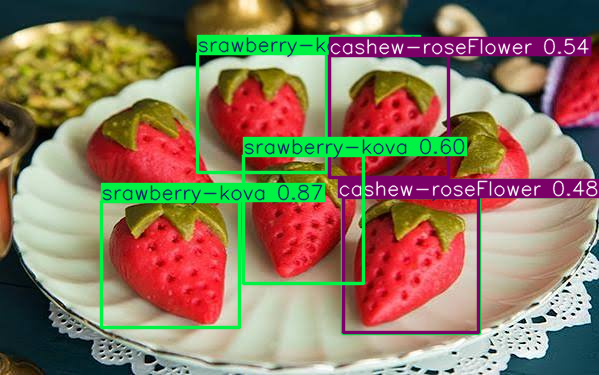

In [70]:
results=model.predict('/content/custom_data/val/images/f944507b-srawberry-kova.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/172de058-Rasmalai10.jpg: 448x640 (no detections), 32.0ms
Speed: 4.7ms preprocess, 32.0ms inference, 0.9ms postprocess per image at shape (1, 3, 448, 640)


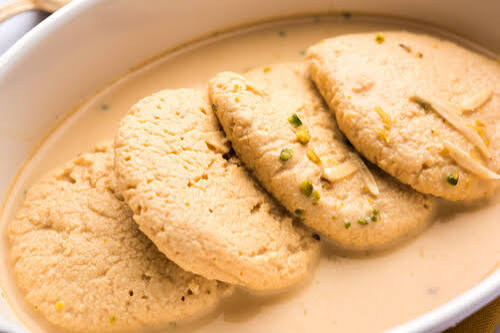

In [72]:
results=model.predict('/content/custom_data/test/images/172de058-Rasmalai10.jpg')
results[0].show()


image 1/1 //content/custom_data/test/images/48e316e1-cashew-bullets3.jpg: 640x640 1 kaju-paan, 56.6ms
Speed: 13.8ms preprocess, 56.6ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 640)


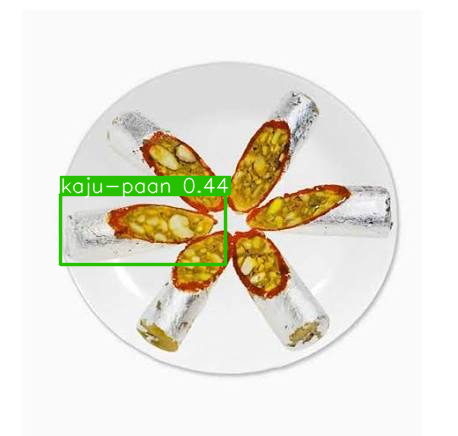

In [74]:
results=model.predict('//content/custom_data/test/images/48e316e1-cashew-bullets3.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/516590b1-osmania-biscuit3.jpg: 640x640 1 osmania-biscuit, 37.5ms
Speed: 3.1ms preprocess, 37.5ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)


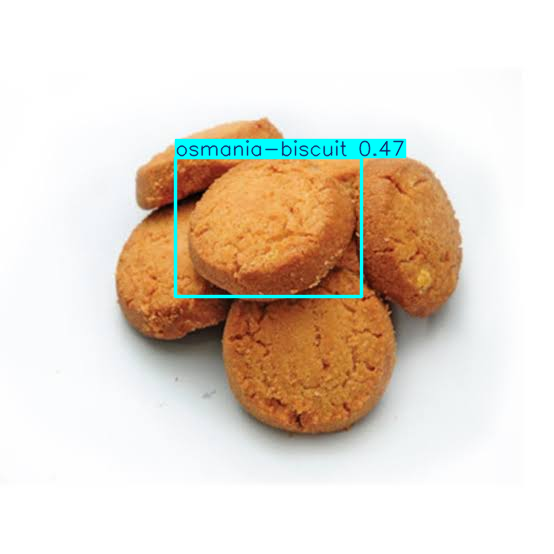

In [75]:
results=model.predict('/content/custom_data/test/images/516590b1-osmania-biscuit3.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/a816d4ff-pappu-chegodi7.jpg: 512x640 6 pappu-chegodis, 35.1ms
Speed: 2.4ms preprocess, 35.1ms inference, 4.3ms postprocess per image at shape (1, 3, 512, 640)


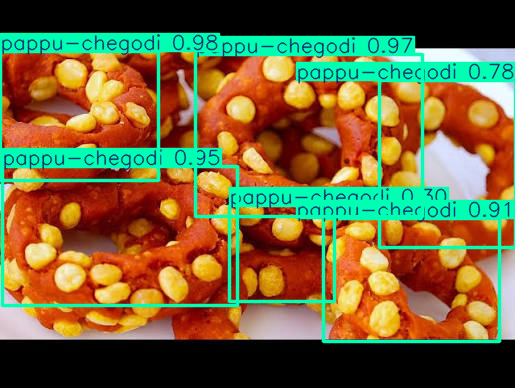

In [78]:
results=model.predict('/content/custom_data/test/images/a816d4ff-pappu-chegodi7.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/fbda9edf-sev8.jpg: 640x640 1 sev, 39.5ms
Speed: 2.9ms preprocess, 39.5ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 640)


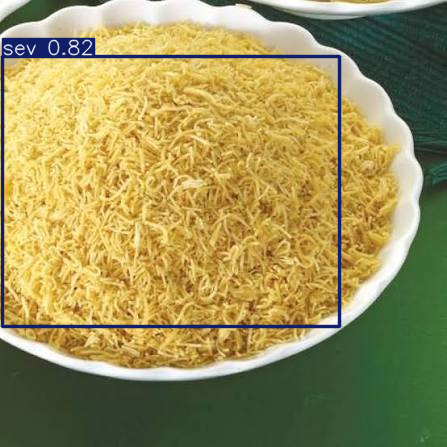

In [79]:
results=model.predict('/content/custom_data/test/images/fbda9edf-sev8.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/dfdfcfe5-Screenshot_2026-11-03_223345.png: 640x608 4 pista-rolls, 51.4ms
Speed: 4.0ms preprocess, 51.4ms inference, 2.6ms postprocess per image at shape (1, 3, 640, 608)


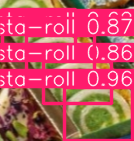

In [80]:
results=model.predict('/content/custom_data/test/images/dfdfcfe5-Screenshot_2026-11-03_223345.png')
results[0].show()


image 1/1 /content/custom_data/test/images/e9516ddd-tirumala-vada5.jpg: 640x384 1 tirumala-vada, 34.1ms
Speed: 6.4ms preprocess, 34.1ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 384)


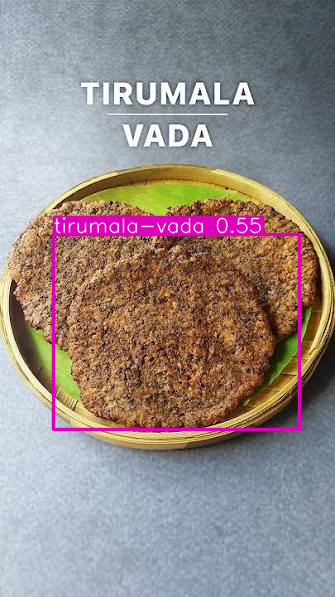

In [81]:
results=model.predict('/content/custom_data/test/images/e9516ddd-tirumala-vada5.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/f873d387-peanut-pakoda.jpg: 640x640 1 kaju-pakoda, 1 peanut-pakoda, 39.0ms
Speed: 2.2ms preprocess, 39.0ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


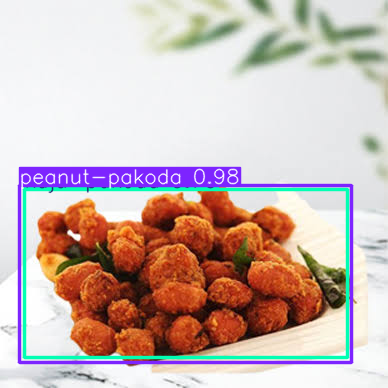

In [82]:
results=model.predict('/content/custom_data/test/images/f873d387-peanut-pakoda.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/e9fe2be9-Rose-laddu4.jpg: 640x640 (no detections), 40.9ms
Speed: 4.6ms preprocess, 40.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


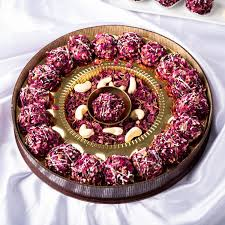

In [83]:
results=model.predict('/content/custom_data/test/images/e9fe2be9-Rose-laddu4.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/9a1f6519-Purnam-Burelu.jpg: 640x384 5 Purnam-Burelus, 1 banana-jamun, 37.2ms
Speed: 5.4ms preprocess, 37.2ms inference, 2.5ms postprocess per image at shape (1, 3, 640, 384)


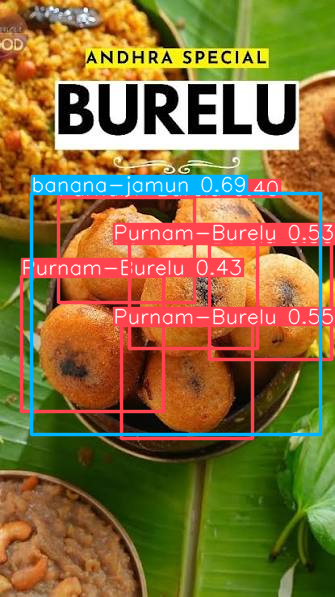

In [84]:
results=model.predict('/content/custom_data/test/images/9a1f6519-Purnam-Burelu.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/b8570bea-Junnu-MilkPudding4.jpg: 640x512 3 Kalakandh-kalakanis, 31.9ms
Speed: 1.9ms preprocess, 31.9ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 512)


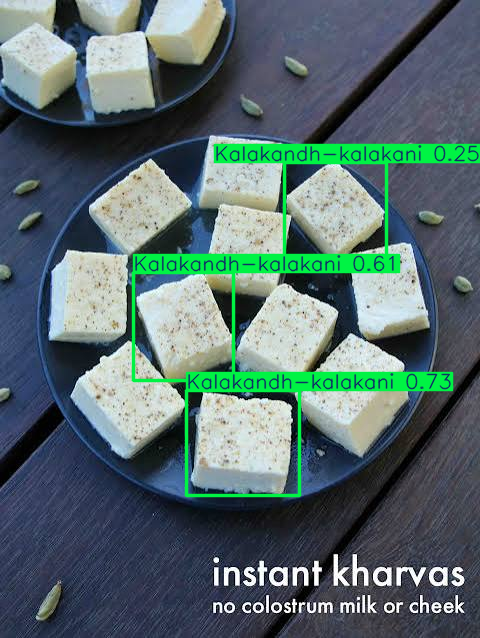

In [85]:
results=model.predict('/content/custom_data/test/images/b8570bea-Junnu-MilkPudding4.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/6d82655a-Tirunelveli-Halwa1.jpg: 640x576 1 Jangri, 1 halwa, 37.0ms
Speed: 2.2ms preprocess, 37.0ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 576)


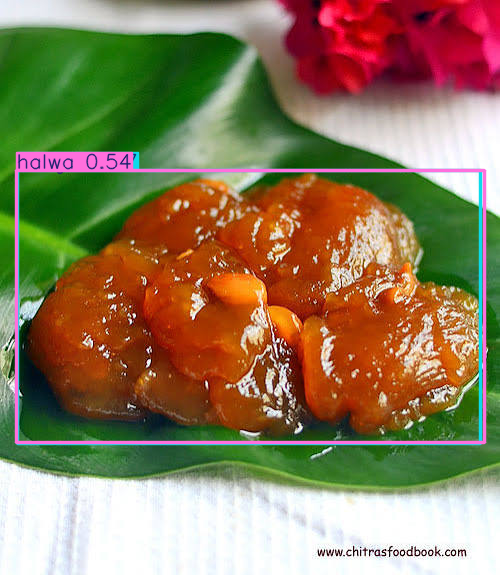

In [86]:
results=model.predict('/content/custom_data/test/images/6d82655a-Tirunelveli-Halwa1.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/86d1052f-kaddu-ka-kheer1.jpg: 640x384 1 Semya, 34.8ms
Speed: 4.1ms preprocess, 34.8ms inference, 3.4ms postprocess per image at shape (1, 3, 640, 384)


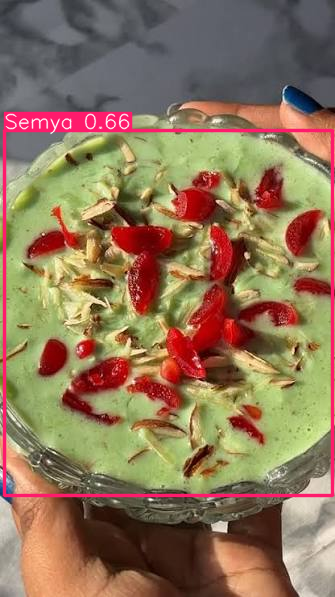

In [87]:
results=model.predict('/content/custom_data/test/images/86d1052f-kaddu-ka-kheer1.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/a2d64a1d-makhana1.jpg: 640x640 1 makhana, 46.6ms
Speed: 3.1ms preprocess, 46.6ms inference, 9.4ms postprocess per image at shape (1, 3, 640, 640)


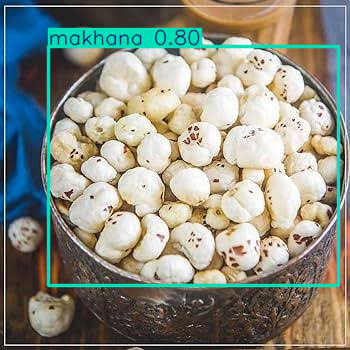

In [88]:
results=model.predict('/content/custom_data/test/images/a2d64a1d-makhana1.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/620dfcef-kara-boondhi6.jpg: 512x640 1 kara-boondhi, 1 salted-channa, 36.8ms
Speed: 3.4ms preprocess, 36.8ms inference, 5.3ms postprocess per image at shape (1, 3, 512, 640)


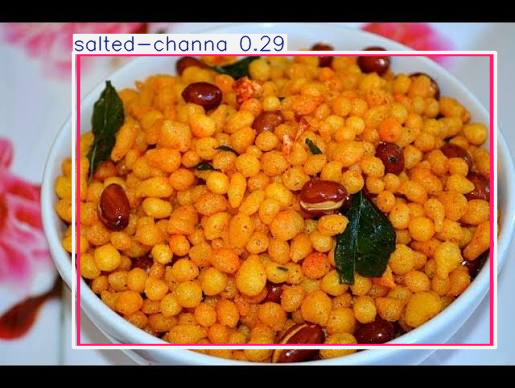

In [89]:
results=model.predict('/content/custom_data/test/images/620dfcef-kara-boondhi6.jpg')
results[0].show()


image 1/1 /content/custom_data/test/images/c5fc0f1c-banana-jamun3.jpg: 640x448 1 banana-jamun, 31.5ms
Speed: 2.3ms preprocess, 31.5ms inference, 6.5ms postprocess per image at shape (1, 3, 640, 448)


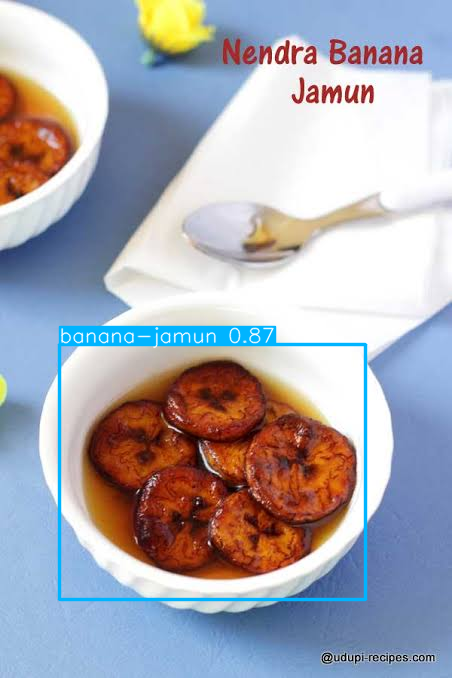

In [91]:
results=model.predict('/content/custom_data/test/images/c5fc0f1c-banana-jamun3.jpg')
results[0].show()


image 1/1 /content/Rose-laddu7.jpg: 640x640 3 Rose-laddus, 81.8ms
Speed: 10.9ms preprocess, 81.8ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)


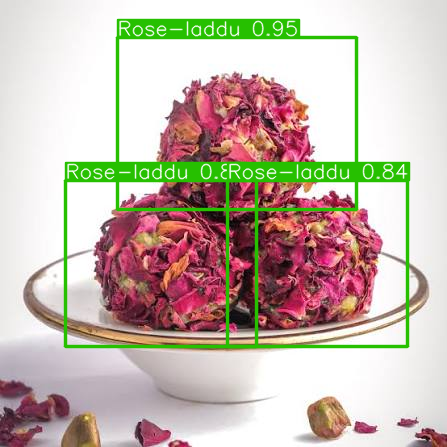

In [92]:
results=model.predict('/content/Rose-laddu7.jpg')
results[0].show()


image 1/1 /content/jelebi16.jpg: 480x640 2 Jelebis, 31.8ms
Speed: 2.4ms preprocess, 31.8ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)


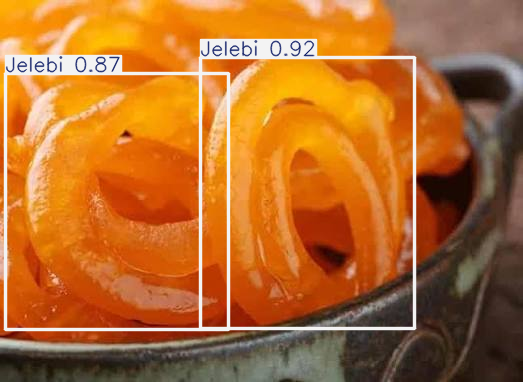

In [93]:
results=model.predict('/content/jelebi16.jpg')
results[0].show()


image 1/1 /content/gulab-jamun3.jpg: 640x640 6 gulab-jamuns, 1 sunnunda, 38.7ms
Speed: 2.6ms preprocess, 38.7ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


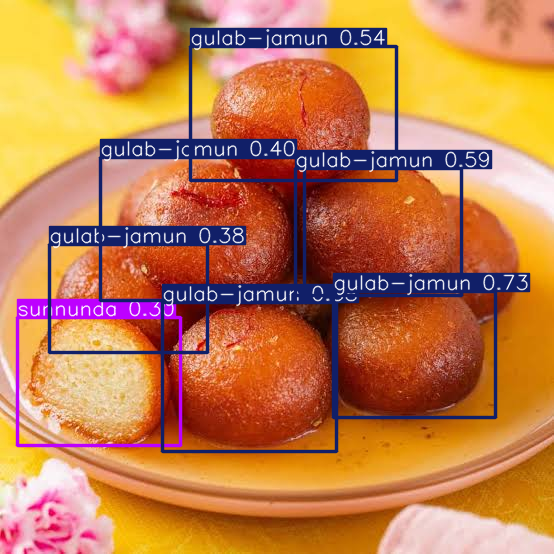

In [94]:
results=model.predict('/content/gulab-jamun3.jpg')
results[0].show()